# 沪深300指数增强策略 V3：收益增强 + 稳健控制版

本版本在“进一步改良版”的基础上继续调整：

1. 加入 IC 正向占比筛选，减少短期噪声因子；
2. 将参数轻微调回收益增强方向，尝试把年化超额收益拉回 3%以上；
3. 加入基于沪深300 MA200 的动态主动风险预算；
4. 组内权重支持 z-score / rank 两种调整方式，默认 z-score；
5. 输出分段绩效，便于论文写样本外稳健性。

注意：建议 `USE_CACHE=False` 从头运行，避免读取旧版 v2 缓存。

In [1]:
# =========================
# 0. 环境与参数
# =========================

from jqdata import *
from jqfactor import get_factor_values, calc_factors, Factor

import os
import warnings
import datetime
import numpy as np
import pandas as pd
import scipy.stats as st
import statsmodels.api as sm
import matplotlib.pyplot as plt

try:
    from tqdm.notebook import tqdm as tqdm_notebook
except Exception:
    from tqdm import tqdm as tqdm_notebook

warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 回测参数
INDEX_SYMBOL = '000300.XSHG'
START_DATE = '2010-01-01'
END_DATE = '2026-06-15'
LAST_TERM_NEXT_DATE = None

# 本地缓存文件名。注意：V3 修改了因子筛选和权重预算，建议 USE_CACHE=False 重新跑。
RAW_FACTOR_FILE = 'index_enhancement_raw.csv'
FACTORS4_FILE = 'factors4_processed_v3.csv'
FACTORS5_FILE = 'factors5_score_v3.csv'
RESULT_FILE = 'result_df_v3.csv'

USE_CACHE = False

# =========================
# V3 收益增强 + 稳健控制参数
# =========================

# 动态因子筛选：比 V2 略放松进攻性，但加入 IC 正向占比过滤，避免假 alpha。
TOP_N_FACTORS = 8
IC_WINDOW = 18
IC_MIN_PERIODS = 12
ICIR_MIN = 0.03
IC_MEAN_MIN = 0.001
IC_POSITIVE_RATIO_MIN = 0.55

# 没有合格 ICIR 信号时，使用核心基本面因子，而不是所有因子等权。
CORE_FACTORS = [
    'BOOK_TO_PRICE_RATIO', 'EPTTM', 'SPTTM',
    'ROE_TTM', 'ROA_TTM',
    'NET_PROFIT_GROWTH_RATE', 'OPERATING_REVENUE_GROWTH_RATE',
    'TOTAL_PROFIT_GROWTH_RATE', 'SUE0', 'SUR0'
]

# 分层内持股数：从 V2 的 3 只调回 2 只，适度提高 alpha 集中度。
N_SELECT_PER_GROUP = 2

# 换手控制：上期持仓若仍在组内前 KEEP_RANK 名，则优先保留。
KEEP_RANK = 5

# 市值分组数量
N_MARKET_CAP_GROUP = 3

# 组内权重：默认用 z-score 调整，更偏收益增强；若想更稳，可改成 'rank'。
SCORE_WEIGHT_METHOD = 'zscore'     # 可选：'zscore' 或 'rank'
SCORE_WEIGHT_ALPHA = 0.70

# 个股权重约束。MAX_ACTIVE_WEIGHT 是不启用动态预算时的默认值。
MAX_STOCK_WEIGHT = 0.035       # 单票最高 3.5%
MAX_ACTIVE_WEIGHT = 0.012      # 默认相对沪深300原权重最高多配 1.2%

# 动态主动风险预算：牛市/强势市场略放开主动偏离，弱势市场收紧主动偏离。
USE_DYNAMIC_RISK_BUDGET = True
MARKET_MA_WINDOW = 200
BULL_SCORE_WEIGHT_ALPHA = 0.70
BEAR_SCORE_WEIGHT_ALPHA = 0.40
BULL_MAX_ACTIVE_WEIGHT = 0.015
BEAR_MAX_ACTIVE_WEIGHT = 0.008

# 交易成本
FEE_RATE = 0.003

In [2]:
# =========================
# 1. 自定义因子
# =========================

class EPTTM(Factor):

    name = 'EPTTM'
    max_window = 1
    dependencies = ['pe_ratio']

    def calc(self, data):
        return (1 / data['pe_ratio']).iloc[0]


class SPTTM(Factor):
    name = 'SPTTM'
    max_window = 1
    dependencies = ['ps_ratio']

    def calc(self, data):
        return (1 / data['ps_ratio']).iloc[0]


class SUE0(Factor):
    '''标准化预期外盈利：带漂移项的季节性随机游走模型。'''
    name = 'SUE0'
    max_window = 1
    fields = ['net_profit_{}'.format(i) if i != 0 else 'net_profit' for i in range(9)]
    dependencies = fields

    def calc(self, data):
        df = pd.concat([v.T for v in data.values()], axis=1)
        df.columns = self.fields
        df = df.fillna(0)

        tmp = df.iloc[:, 1:5].values - df.iloc[:, 5:].values
        C = np.mean(tmp, axis=1)
        epsilon = np.std(tmp, axis=1)
        epsilon = np.where(epsilon == 0, np.nan, epsilon)

        Q = df.iloc[:, 4] + C + epsilon
        return (df.iloc[:, 0] - Q) / epsilon


class SUR0(Factor):
    '''标准化预期外收入：带漂移项的季节性随机游走模型。'''
    name = 'SUR0'
    max_window = 1
    fields = ['operating_revenue_{}'.format(i) if i != 0 else 'operating_revenue' for i in range(9)]
    dependencies = fields

    def calc(self, data):
        df = pd.concat([v.T for v in data.values()], axis=1)
        df.columns = self.fields
        df = df.fillna(0)

        tmp = df.iloc[:, 1:5].values - df.iloc[:, 5:].values
        C = np.mean(tmp, axis=1)
        epsilon = np.std(tmp, axis=1)
        epsilon = np.where(epsilon == 0, np.nan, epsilon)

        Q = df.iloc[:, 4] + C + epsilon
        return (df.iloc[:, 0] - Q) / epsilon


class DELTAROE(Factor):
    name = 'DELTAROE'
    max_window = 1
    dependencies = ['roe', 'roe_4']

    def calc(self, data):
        return (data['roe'] - data['roe_4']).iloc[0]


class DELTAROA(Factor):
    name = 'DELTAROA'
    max_window = 1
    dependencies = ['roa', 'roa_4']

    def calc(self, data):
        return (data['roa'] - data['roa_4']).iloc[0]


class ILLIQ(Factor):
    name = 'ILLIQ'
    max_window = 21
    dependencies = ['close', 'money']

    def calc(self, data):
        abs_ret = np.abs(data['close'].pct_change().shift(1).iloc[1:])
        return (abs_ret / data['money'].iloc[1:]).mean()


class ATR1M(Factor):
    name = 'ATR1M'
    max_window = 22
    dependencies = ['close', 'high', 'low']

    def calc(self, data):
        high = data['high'].shift(1).iloc[1:]
        low = data['low'].shift(1).iloc[1:]
        close = data['close'].shift(1).iloc[1:]

        tmp = np.maximum(high - low, np.abs(close.shift(1) - high))
        tr = np.maximum(tmp, np.abs(close.shift(1) - low))
        return tr.iloc[-20:].mean()


class ATR3M(Factor):
    name = 'ATR3M'
    max_window = 62
    dependencies = ['close', 'high', 'low']

    def calc(self, data):
        high = data['high'].shift(1).iloc[1:]
        low = data['low'].shift(1).iloc[1:]
        close = data['close'].shift(1).iloc[1:]

        tmp = np.maximum(high - low, np.abs(close.shift(1) - high))
        tr = np.maximum(tmp, np.abs(close.shift(1) - low))
        return tr.iloc[-60:].mean()

In [3]:
# =========================
# 2. 股票筛选与因子获取工具
# =========================

class FilterStocks(object):
    '''
    获取某日指数成分股，并做基础过滤：
    1. 剔除 ST；
    2. 剔除上市不足 N 个月的新股；
    3. 剔除近期停牌/交易不活跃股票。
    '''

    def __init__(self, index_symbol, watch_date, N=12, active_day=15):
        self.index_symbol = index_symbol
        self.watch_date = pd.Timestamp(watch_date).date()
        self.N = int(N)
        self.active_day = int(active_day)

    @property
    def Get_Stocks(self):
        if self.index_symbol in ['A', 'ALL']:
            stocks = get_index_stocks('000002.XSHG', date=self.watch_date) + \
                     get_index_stocks('399107.XSHE', date=self.watch_date)
        else:
            stocks = get_index_stocks(self.index_symbol, date=self.watch_date)

        stocks = list(dict.fromkeys(stocks))
        if len(stocks) == 0:
            return []

        st_data = get_extras('is_st', stocks, end_date=self.watch_date, count=1).iloc[0]
        stocks = st_data[st_data == False].index.tolist()
        if len(stocks) == 0:
            return []

        stocks = self.delete_new_stock(stocks, self.watch_date, self.N)
        if len(stocks) == 0:
            return []

        stocks = self.delete_pause(stocks, self.watch_date, self.active_day)
        return stocks

    @staticmethod
    def delete_new_stock(stocks, begin_date, n_months=12):
        cutoff = (pd.Timestamp(begin_date) - pd.DateOffset(months=n_months)).date()
        return [code for code in stocks if get_security_info(code).start_date < cutoff]

    @staticmethod
    def delete_pause(stocks, begin_date, active_day=15):
        if len(stocks) == 0:
            return []

        trade_days = get_trade_days(end_date=begin_date, count=active_day)
        if len(trade_days) == 0:
            return []

        end_trade_day = trade_days[-1]
        end_trade_str = pd.Timestamp(end_trade_day).strftime('%Y-%m-%d')

        df = get_price(stocks, end_date=end_trade_day, count=active_day,
                       fields='paused', panel=False)
        if df is None or len(df) == 0:
            return []

        df['time_str'] = pd.to_datetime(df['time']).dt.strftime('%Y-%m-%d')

        tradable_today = df.query('paused == 0 and time_str == @end_trade_str')['code'].unique().tolist()
        if len(tradable_today) == 0:
            return []

        traded_days = (df[df['code'].isin(tradable_today)]
                       .assign(is_traded=lambda x: x['paused'] == 0)
                       .groupby('code')['is_traded'].sum())

        return traded_days[traded_days >= active_day].index.tolist()


def GetTradePeriod(start_date, end_date, freq='ME'):
    '''
    获取调仓日期。
    freq='ME'：月末；'MS'：月初；'QE'：季末。
    '''
    days = pd.Index(pd.to_datetime(get_trade_days(start_date, end_date)))
    idx_df = days.to_frame()

    if freq[-1] == 'E':
        day_range = idx_df.resample(freq[0]).last()
    else:
        day_range = idx_df.resample(freq[0]).first()

    day_range = day_range[0].dt.date
    return day_range.dropna().values.tolist()


def dict2frame(dic):
    '''将聚宽因子字典转成 DataFrame。'''
    tmp_v = [v.T for v in dic.values()]
    name = [k.upper() for k in dic.keys()]
    df = pd.concat(tmp_v, axis=1)
    df.columns = name
    return df


def get_stock_ind(securities, watch_date, level='sw_l1', method='industry_code'):
    '''获取申万一级行业代码。'''
    industry_dict = get_industry(securities, watch_date)

    industry_ser = pd.Series({
        k: v.get(level, {method: np.nan})[method]
        for k, v in industry_dict.items()
    })

    industry_ser.name = method.upper()
    return industry_ser


def IndusrtyMktcap(securities, watch_date):
    '''获取行业和市值辅助变量。'''
    industry_ser = get_stock_ind(securities, watch_date)

    mkt_cap = (get_valuation(securities, end_date=watch_date,
                             fields='market_cap', count=1)
               .set_index('code')['market_cap'])

    return pd.concat([industry_ser, mkt_cap], axis=1)


def query_model_factor(securities, watch_date):
    '''获取本文使用的多因子数据。'''
    base_fields = [
        'natural_log_of_market_cap', 'book_to_price_ratio',
        'ROC20', 'ROC60',
        'net_profit_growth_rate', 'operating_revenue_growth_rate',
        'total_profit_growth_rate', 'roe_ttm',
        'roa_ttm', 'VOL20', 'VOL60'
    ]

    part_a = get_factor_values(securities, base_fields,
                               start_date=watch_date, end_date=watch_date)
    part_a = dict2frame(part_a)

    custom_fields = [
        EPTTM(), SPTTM(), SUE0(), SUR0(),
        DELTAROE(), DELTAROA(), ILLIQ(), ATR1M(), ATR3M()
    ]

    part_b = calc_factors(securities, custom_fields,
                          start_date=watch_date, end_date=watch_date)
    part_b = dict2frame(part_b)

    part_c = IndusrtyMktcap(securities, watch_date)

    return pd.concat([part_a, part_b, part_c], axis=1)


def get_factor(func, index_symbol, start, end, freq='ME'):
    '''逐月获取因子数据。'''
    periods = GetTradePeriod(start, end, freq)

    factor_dic = {}
    for d in tqdm_notebook(periods):
        securities = FilterStocks(index_symbol, d.strftime('%Y-%m-%d'), N=12).Get_Stocks
        if len(securities) == 0:
            continue
        factor_dic[pd.to_datetime(d)] = func(securities, d)

    factor_df = pd.concat(factor_dic)
    factor_df.index.names = ['date', 'code']
    return factor_df.sort_index()

In [4]:
# =========================
# 3. 获取或读取原始因子
# =========================

if USE_CACHE and os.path.exists(RAW_FACTOR_FILE):
    factors = pd.read_csv(RAW_FACTOR_FILE, index_col=[0, 1],
                          parse_dates=[0], dtype={'INDUSTRY_CODE': str})
    factors.index.names = ['date', 'code']
else:
    factors = get_factor(query_model_factor, INDEX_SYMBOL, START_DATE, END_DATE)
    factors.to_csv(RAW_FACTOR_FILE)

print(factors.shape)
factors.head()

100%|██████████| 198/198 [07:54<00:00,  2.36s/it]


(55136, 22)


OPERATING_REVENUE_GROWTH_RATE     ...      market_cap
date       code                                           ...                
2010-01-29 000001.XSHE                       0.080103     ...        673.8791
           000002.XSHE                       0.093374     ...       1026.9526
           000009.XSHE                       0.121046     ...        113.7653
           000012.XSHE                       0.031055     ...        223.1420
           000021.XSHE                      -0.217991     ...        114.6892

[5 rows x 22 columns]

In [5]:
# =========================
# 4. 因子预处理函数
# =========================

def get_factor_cols(df):
    return [c for c in df.columns if c not in ['INDUSTRY_CODE', 'market_cap', 'NEXT_RET', 'SCORE']]


def apply_by_date(df, func):
    '''兼容旧 pandas 的按日期 apply。'''
    parts = []
    for d, g in df.groupby(level='date'):
        parts.append(func(g))
    return pd.concat(parts).sort_index()


def fillna_by_industry(data):
    '''用同一行业的截面中位数填补缺失值，仍缺失则填 0。'''
    data_ = data.copy()
    data_ = data_[data_['INDUSTRY_CODE'].notnull()]

    factor_cols = get_factor_cols(data_)
    data_[factor_cols] = data_.groupby('INDUSTRY_CODE')[factor_cols].transform(
        lambda x: x.fillna(x.median())
    )
    data_[factor_cols] = data_[factor_cols].fillna(0)
    return data_


def extreme_process_MAD(data, num=3):
    '''MAD 去极值。'''
    data_ = data.copy()
    factor_cols = get_factor_cols(data_)

    median = data_[factor_cols].median(axis=0)
    mad = abs(data_[factor_cols].sub(median, axis=1)).median(axis=0)
    lower = median - num * 1.4826 * mad
    upper = median + num * 1.4826 * mad

    data_.loc[:, factor_cols] = data_[factor_cols].clip(lower=lower, upper=upper, axis=1)
    return data_


def neutralization(data, skip_neutral=('NATURAL_LOG_OF_MARKET_CAP',)):
    '''对因子做行业、市值中性化；规模因子本身不做市值中性化。'''
    data_ = data.copy()
    factor_cols = get_factor_cols(data_)
    skip_neutral = set(skip_neutral)

    X = pd.get_dummies(data_['INDUSTRY_CODE'], drop_first=True)
    X['ln_market_cap'] = np.log(data_['market_cap'].astype(float) * 100000000)
    X = sm.add_constant(X.astype(float), has_constant='add').fillna(0)

    resid_df = pd.DataFrame(index=data_.index)

    for col in factor_cols:
        y = data_[col].astype(float)

        # 关键修正：规模因子不再用市值回归掉，否则会把它自身解释掉。
        if col in skip_neutral:
            resid_df[col] = y
            continue

        try:
            model = sm.OLS(y, X, missing='drop').fit()
            resid_df[col] = model.resid
        except Exception:
            resid_df[col] = y - y.mean()

    resid_df['INDUSTRY_CODE'] = data_['INDUSTRY_CODE']
    resid_df['market_cap'] = data_['market_cap']
    return resid_df


def data_scale_Z_Score(data):
    '''Z-score 标准化。'''
    data_ = data.copy()
    factor_cols = get_factor_cols(data_)

    mean = data_[factor_cols].mean()
    std = data_[factor_cols].std().replace(0, np.nan)

    data_[factor_cols] = (data_[factor_cols] - mean) / std
    data_[factor_cols] = data_[factor_cols].fillna(0)
    return data_

In [6]:
# =========================
# 5. 执行因子预处理
# =========================

if USE_CACHE and os.path.exists(FACTORS4_FILE):
    factors4 = pd.read_csv(FACTORS4_FILE, index_col=[0, 1],
                           parse_dates=[0], dtype={'INDUSTRY_CODE': str})
    factors4.index.names = ['date', 'code']
else:
    factors1 = apply_by_date(factors, fillna_by_industry)
    factors2 = apply_by_date(factors1, extreme_process_MAD)
    factors3 = apply_by_date(factors2, neutralization)
    factors4 = apply_by_date(factors3, data_scale_Z_Score)
    factors4.to_csv(FACTORS4_FILE)

print(factors4.shape)
factors4.head()

(55136, 22)


OPERATING_REVENUE_GROWTH_RATE     ...      market_cap
date       code                                           ...                
2010-01-29 000001.XSHE                       0.209363     ...        673.8791
           000002.XSHE                      -0.490395     ...       1026.9526
           000009.XSHE                      -0.263084     ...        113.7653
           000012.XSHE                      -1.407734     ...        223.1420
           000021.XSHE                      -0.870489     ...        114.6892

[5 rows x 22 columns]

In [7]:
# =========================
# 6. 对称正交
# =========================

def lowdin_orthogonal(data):
    '''Lowdin 对称正交。'''
    data_ = data.copy()
    factor_cols = get_factor_cols(data_)

    F = data_[factor_cols].astype(float).values
    M = F.T.dot(F)

    eigvals, eigvecs = np.linalg.eigh(M)
    eigvals = np.clip(eigvals, 1e-12, None)

    S = eigvecs.dot(np.diag(1 / np.sqrt(eigvals))).dot(eigvecs.T)
    data_.loc[:, factor_cols] = F.dot(S)

    return data_


def get_next_ret(factor, keep_last_term=False, last_term_next_date=None):
    '''
    根据调仓日收盘价计算每只股票下一期收益。
    index: (date, code)
    '''
    securities = sorted(factor.index.get_level_values('code').unique().tolist())
    periods = sorted(factor.index.get_level_values('date').unique())

    date_list = [pd.to_datetime(d).strftime('%Y-%m-%d') for d in periods]

    if keep_last_term:
        if last_term_next_date is None:
            raise ValueError('keep_last_term=True 时必须提供 last_term_next_date')
        date_list = date_list + [last_term_next_date]

    close_list = []
    for d in tqdm_notebook(date_list):
        price = get_price(securities, end_date=d, count=1, fields='close', panel=False)
        if price is None or len(price) == 0:
            continue
        tmp = price.pivot(index='time', columns='code', values='close')
        tmp.index = pd.to_datetime([d])
        close_list.append(tmp)

    close = pd.concat(close_list).sort_index()
    ret = close.pct_change().shift(-1)

    if keep_last_term:
        ret = ret.iloc[:-1]

    ret_long = ret.stack()
    ret_long.index.names = ['date', 'code']
    ret_long.name = 'NEXT_RET'
    return ret_long

In [8]:
# =========================
# 7. 统一因子方向、动态因子筛选、ICIR 权重、综合得分
# =========================

FACTOR_DIRECTION = {
    'NATURAL_LOG_OF_MARKET_CAP': -1,
    'ROC20': -1,
    'ROC60': -1,
    'VOL20': -1,
    'VOL60': -1,
    'ILLIQ': -1,
    'ATR1M': -1,
    'ATR3M': -1,
}


def align_factor_direction(df, direction=FACTOR_DIRECTION):
    '''统一因子方向，使因子值越大越好。'''
    out = df.copy()
    for col, sign in direction.items():
        if col in out.columns:
            out[col] = out[col] * sign
    return out


def safe_spearman(x, y):
    valid = x.notna() & y.notna()
    if valid.sum() < 10:
        return np.nan
    if x[valid].nunique() <= 1 or y[valid].nunique() <= 1:
        return np.nan
    return st.spearmanr(x[valid], y[valid])[0]


def calc_rank_IC(factor):
    '''逐月计算每个因子的 Rank IC。'''
    factor_cols = get_factor_cols(factor)

    out = []
    idx = []
    for d, g in factor.groupby(level='date'):
        ser = pd.Series({col: safe_spearman(g[col], g['NEXT_RET']) for col in factor_cols})
        out.append(ser)
        idx.append(d)

    IC = pd.DataFrame(out, index=pd.to_datetime(idx))
    IC.index.name = 'date'
    return IC


def _normalize_positive_or_nan(row):
    '''只归一化正权重；整行无正权重时返回 NaN，交给后续沿用上一期或核心因子兜底。'''
    row = row.replace([np.inf, -np.inf], np.nan).fillna(0)
    row[row < 0] = 0
    if row.sum() <= 0:
        return pd.Series(np.nan, index=row.index)
    return row / row.sum()


def _default_core_weight(columns, core_factors=None):
    '''构造核心因子兜底权重，避免无信号时所有因子机械等权。'''
    core_factors = core_factors or []
    cols = list(columns)
    use_cols = [c for c in core_factors if c in cols]
    if len(use_cols) == 0:
        use_cols = cols

    w = pd.Series(0.0, index=cols)
    w.loc[use_cols] = 1.0 / len(use_cols)
    return w


def _clean_weight_table(weights, default_weight):
    '''权重表清洗：无信号则沿用上一期；开头无上一期则用核心因子兜底。'''
    cleaned = []
    prev = None

    for _, row in weights.iterrows():
        row = row.replace([np.inf, -np.inf], np.nan)

        if row.notna().sum() == 0 or row.fillna(0).sum() <= 0:
            use = prev.copy() if prev is not None else default_weight.copy()
        else:
            use = row.fillna(0)
            use[use < 0] = 0
            if use.sum() <= 0:
                use = prev.copy() if prev is not None else default_weight.copy()
            else:
                use = use / use.sum()

        cleaned.append(use)
        prev = use.copy()

    out = pd.DataFrame(cleaned, index=weights.index, columns=weights.columns)
    out.index.name = 'date'
    return out


def IR_weight_dynamic_filter(factor,
                             window=18,
                             min_periods=12,
                             top_n=8,
                             icir_min=0.03,
                             ic_mean_min=0.001,
                             ic_positive_ratio_min=0.55,
                             shift_weight=True,
                             core_factors=None,
                             return_ic=False):
    '''
    动态因子筛选 + 滚动 ICIR 加权。

    改良点：
    1. 在 ICIR 和 IC 均值之外，新增 IC 正向占比过滤；
    2. 只保留多数月份方向正确、且 ICIR 达标的因子；
    3. 无合格因子时不再所有因子等权，而是沿用上一期有效权重；
    4. 样本开头无上一期权重时，使用核心基本面因子兜底；
    5. 权重整体 shift(1)，避免未来函数。
    '''
    IC = calc_rank_IC(factor)

    rolling_mean = IC.rolling(window=window, min_periods=min_periods).mean()
    rolling_std = IC.rolling(window=window, min_periods=min_periods).std()
    icir = rolling_mean / rolling_std

    # 新增：IC 正向占比。要求过去窗口中多数月份 Rank IC 为正，避免少数极端月份抬高 ICIR。
    def _positive_ratio(x):
        x = pd.Series(x).dropna()
        if len(x) == 0:
            return np.nan
        return (x > 0).mean()

    ic_positive_ratio = IC.rolling(window=window, min_periods=min_periods).apply(
        _positive_ratio,
        raw=False
    )

    candidate = icir.copy()
    candidate = candidate.where(
        (icir > icir_min) &
        (rolling_mean > ic_mean_min) &
        (ic_positive_ratio >= ic_positive_ratio_min),
        0
    )

    if top_n is not None and top_n > 0 and top_n < len(candidate.columns):
        ranks = candidate.rank(axis=1, ascending=False, method='first')
        candidate = candidate.where(ranks <= top_n, 0)

    raw_weights = candidate.apply(_normalize_positive_or_nan, axis=1)

    if shift_weight:
        raw_weights = raw_weights.shift(1)

    default_weight = _default_core_weight(raw_weights.columns, core_factors=core_factors)
    weights = _clean_weight_table(raw_weights, default_weight=default_weight)

    # selected_flag 表示最终用于打分的因子。
    selected_flag = weights > 0
    selected_flag.index.name = 'date'

    if return_ic:
        return weights, IC, icir, ic_positive_ratio, selected_flag

    return weights

In [9]:
# =========================
# 8. 生成 SCORE：动态因子筛选版
# =========================

if USE_CACHE and os.path.exists(FACTORS5_FILE):
    factors5 = pd.read_csv(FACTORS5_FILE, index_col=[0, 1],
                           parse_dates=[0], dtype={'INDUSTRY_CODE': str})
    factors5.index.names = ['date', 'code']
else:
    factors5 = apply_by_date(factors4, lowdin_orthogonal)
    factors5 = align_factor_direction(factors5)

    keep_last = LAST_TERM_NEXT_DATE is not None
    factors5['NEXT_RET'] = get_next_ret(
        factors5,
        keep_last_term=keep_last,
        last_term_next_date=LAST_TERM_NEXT_DATE
    )

    factor_names = get_factor_cols(factors5)
    weights, IC, icir, ic_positive_ratio, selected_flag = IR_weight_dynamic_filter(
        factors5,
        window=IC_WINDOW,
        min_periods=IC_MIN_PERIODS,
        top_n=TOP_N_FACTORS,
        icir_min=ICIR_MIN,
        ic_mean_min=IC_MEAN_MIN,
        ic_positive_ratio_min=IC_POSITIVE_RATIO_MIN,
        shift_weight=True,
        core_factors=CORE_FACTORS,
        return_ic=True
    )

    score_matrix = factors5[factor_names].mul(weights, level='date')
    factors5['SCORE'] = score_matrix.sum(axis=1)

    factors5.to_csv(FACTORS5_FILE)
    IC.to_csv('rank_ic_v3.csv')
    icir.to_csv('rolling_icir_v3.csv')
    ic_positive_ratio.to_csv('rolling_ic_positive_ratio_v3.csv')
    weights.to_csv('dynamic_factor_weights_v3.csv')
    selected_flag.to_csv('dynamic_factor_selected_v3.csv')

print(factors5.shape)
factors5[['SCORE', 'NEXT_RET']].head()

100%|██████████| 198/198 [00:21<00:00,  9.09it/s]


(55136, 24)


SCORE  NEXT_RET
date       code                           
2010-01-29 000001.XSHE -0.020176  0.033868
           000002.XSHE  0.000397  0.008772
           000009.XSHE -0.012885  0.082589
           000012.XSHE -0.023025  0.068702
           000021.XSHE  0.006916  0.001340

In [10]:
# =========================
# 9. V3 分层抽样函数：收益增强 + 动态主动风险预算
# =========================

def get_weighs(symbol, start, end, method='cons'):
    '''获取月度指数成分权重。'''
    periods = GetTradePeriod(start, end, 'ME')

    if method == 'cons':
        frames = []
        for d in tqdm_notebook(periods):
            tmp = get_index_weights(symbol, date=d).copy()
            tmp = tmp.reset_index().rename(columns={'index': 'code'})
            if 'date' in tmp.columns:
                tmp = tmp.drop(columns=['date'])
            tmp['date'] = pd.to_datetime(d)
            tmp['weight'] = tmp['weight'] / 100.0
            frames.append(tmp[['date', 'code', 'weight']])

        out = pd.concat(frames)
        out = out.set_index(['date', 'code']).sort_index()
        return out

    raise ValueError('method 目前仅支持 cons')


def get_dynamic_risk_budget(symbol,
                            dates,
                            use_dynamic=True,
                            ma_window=200,
                            bull_score_alpha=0.70,
                            bear_score_alpha=0.40,
                            bull_max_active_weight=0.015,
                            bear_max_active_weight=0.008,
                            default_score_alpha=0.70,
                            default_max_active_weight=0.012):
    '''
    生成每个调仓日的动态主动风险预算。

    规则：
    1. 指数收盘价 >= MA200：市场状态偏强，允许更高主动偏离和得分调整强度；
    2. 指数收盘价 < MA200：市场状态偏弱，收紧主动偏离，降低超额回撤风险；
    3. 只使用调仓日及以前的指数价格，不使用未来数据。
    '''
    rows = []

    for d in sorted(pd.to_datetime(dates)):
        d_str = pd.Timestamp(d).strftime('%Y-%m-%d')

        state = 'neutral'
        index_close = np.nan
        index_ma = np.nan
        score_alpha = default_score_alpha
        max_active = default_max_active_weight

        if use_dynamic:
            try:
                price = get_price(symbol, end_date=d_str, count=ma_window + 1, fields='close')
                if price is not None and len(price) > 0:
                    if isinstance(price, pd.DataFrame) and 'close' in price.columns:
                        close_ser = price['close'].astype(float).dropna()
                    else:
                        close_ser = pd.Series(price).astype(float).dropna()

                    if len(close_ser) >= max(20, ma_window // 2):
                        index_close = float(close_ser.iloc[-1])
                        index_ma = float(close_ser.iloc[-min(ma_window, len(close_ser)):].mean())

                        if index_close < index_ma:
                            state = 'bear'
                            score_alpha = bear_score_alpha
                            max_active = bear_max_active_weight
                        else:
                            state = 'bull'
                            score_alpha = bull_score_alpha
                            max_active = bull_max_active_weight
            except Exception as e:
                # 若指数价格获取失败，则回到默认预算，保证主流程不中断。
                state = 'neutral'

        rows.append({
            'date': d,
            'market_state': state,
            'index_close': index_close,
            'index_ma': index_ma,
            'score_weight_alpha_dynamic': score_alpha,
            'max_active_weight_dynamic': max_active
        })

    budget = pd.DataFrame(rows)
    budget['date'] = pd.to_datetime(budget['date'])
    return budget.set_index('date')


def get_group(x, N=3):
    '''把一组市值按从小到大分为 N 组。'''
    x = x.astype(float)

    if x.notna().sum() < N:
        return pd.Series(np.nan, index=x.index)

    try:
        return pd.qcut(x.rank(method='first'), q=N, labels=False) + 1
    except Exception:
        return pd.Series(np.nan, index=x.index)


def _choose_with_turnover_control(g, prev_codes, n_select=3, keep_rank=8):
    '''
    在单个行业—市值小组内选股。
    先保留仍处于前 keep_rank 名的上期持仓，再用本期 SCORE 最高股票补足。
    '''
    g = g.sort_values('SCORE', ascending=False).copy()
    g['rank_in_group'] = np.arange(1, len(g) + 1)

    keep_codes = []
    prev_codes = prev_codes or []

    for code in prev_codes:
        tmp = g[g['code'] == code]
        if len(tmp) == 0:
            continue
        rank = int(tmp['rank_in_group'].iloc[0])
        if rank <= keep_rank:
            keep_codes.append(code)
        if len(keep_codes) >= n_select:
            break

    fill_codes = [c for c in g['code'].tolist() if c not in keep_codes]
    chosen_codes = (keep_codes + fill_codes)[:min(n_select, len(g))]

    selected = g[g['code'].isin(chosen_codes)].copy()
    return selected, chosen_codes


def _normalize_to_target(raw_w, target_sum):
    '''把一组 raw_w 归一到 target_sum；raw_w 全零时等权。'''
    raw_w = raw_w.replace([np.inf, -np.inf], np.nan).fillna(0).clip(lower=0)
    if raw_w.sum() <= 0:
        return pd.Series(target_sum / len(raw_w), index=raw_w.index)
    return raw_w / raw_w.sum() * target_sum


def _apply_date_level_upper_cap(date_df,
                                weight_col='w_prelim',
                                bench_col='weight',
                                max_stock_weight=0.03,
                                max_active_weight=0.01,
                                max_iter=20):
    '''
    对单期组合施加个股上限：
    1. 单票最高 max_stock_weight；
    2. 单票相对基准最多多配 max_active_weight；
    3. 超出部分在未触及上限的股票之间按原权重比例再分配。
    若股票数量过少导致约束不可行，会自动退化为按上限归一化。
    '''
    g = date_df.copy()
    w = g[weight_col].astype(float).replace([np.inf, -np.inf], np.nan).fillna(0).clip(lower=0)

    if w.sum() <= 0:
        w = pd.Series(1.0 / len(g), index=g.index)
    else:
        w = w / w.sum()

    upper = np.minimum(max_stock_weight, g[bench_col].astype(float).fillna(0) + max_active_weight)
    upper = pd.Series(upper, index=g.index).clip(lower=1e-8)

    # 如果约束不可行，退化为上限权重归一化。
    if upper.sum() < 1:
        g['w'] = upper / upper.sum()
        return g

    fixed = pd.Series(False, index=g.index)

    for _ in range(max_iter):
        over = (w > upper) & (~fixed)
        if not over.any():
            break

        fixed = fixed | over
        w.loc[fixed] = upper.loc[fixed]

        residual = 1 - w.loc[fixed].sum()
        free = ~fixed
        if residual <= 0 or free.sum() == 0:
            break

        base = g.loc[free, weight_col].astype(float).replace([np.inf, -np.inf], np.nan).fillna(0).clip(lower=0)
        if base.sum() <= 0:
            w.loc[free] = residual / free.sum()
        else:
            w.loc[free] = base / base.sum() * residual

    w = w.clip(lower=0)
    g['w'] = w / w.sum()
    return g


def stratified_sampling_improved(symbol, start, end, factors,
                                 n_group=3,
                                 n_select_per_group=2,
                                 keep_rank=5,
                                 score_weight_alpha=0.70,
                                 score_weight_method='zscore',
                                 max_stock_weight=0.035,
                                 max_active_weight=0.012,
                                 use_dynamic_risk_budget=True,
                                 market_ma_window=200,
                                 bull_score_weight_alpha=0.70,
                                 bear_score_weight_alpha=0.40,
                                 bull_max_active_weight=0.015,
                                 bear_max_active_weight=0.008):
    '''
    改良版行业—市值分层抽样。

    V3 主要改动：
    1. 每组默认选择 2 只股票，适度提高 alpha 集中度；
    2. 组内权重不再平分，而是“基准权重 × 得分调整”；
    3. 支持 z-score 与 rank 两种得分调整方式；
    4. 加入单票权重上限和相对基准多配上限；
    5. 新增基于沪深300是否跌破 MA200 的动态主动风险预算；
    6. 保留换手控制逻辑。
    '''
    factors_ = factors.copy()
    bench_weight = get_weighs(symbol, start, end, method='cons')

    tmp = factors_.join(bench_weight, how='inner')
    tmp = tmp.dropna(subset=['INDUSTRY_CODE', 'market_cap', 'SCORE', 'weight'])
    tmp = tmp.reset_index()
    tmp['date'] = pd.to_datetime(tmp['date'])

    # 动态主动风险预算：强势市场略提高进攻性，弱势市场收缩主动偏离。
    budget = get_dynamic_risk_budget(
        symbol,
        tmp['date'].unique(),
        use_dynamic=use_dynamic_risk_budget,
        ma_window=market_ma_window,
        bull_score_alpha=bull_score_weight_alpha,
        bear_score_alpha=bear_score_weight_alpha,
        bull_max_active_weight=bull_max_active_weight,
        bear_max_active_weight=bear_max_active_weight,
        default_score_alpha=score_weight_alpha,
        default_max_active_weight=max_active_weight
    ).reset_index()

    tmp = tmp.merge(budget, on='date', how='left')
    tmp['score_weight_alpha_dynamic'] = tmp['score_weight_alpha_dynamic'].fillna(score_weight_alpha)
    tmp['max_active_weight_dynamic'] = tmp['max_active_weight_dynamic'].fillna(max_active_weight)
    tmp['market_state'] = tmp['market_state'].fillna('neutral')

    tmp['GROUP'] = tmp.groupby(['date', 'INDUSTRY_CODE'])['market_cap'].transform(
        lambda x: get_group(x, N=n_group)
    )
    tmp = tmp.dropna(subset=['GROUP'])

    group_cols = ['date', 'INDUSTRY_CODE', 'GROUP']
    group_cols_no_date = ['INDUSTRY_CODE', 'GROUP']

    # 每个行业—市值小组在基准指数中的总权重。
    group_weight = tmp.groupby(group_cols)['weight'].sum()

    selected_frames = []
    prev_hold_by_group = {}

    for d in sorted(tmp['date'].unique()):
        date_df = tmp[tmp['date'] == d].copy()

        for key, g in date_df.groupby(group_cols_no_date):
            prev_codes = prev_hold_by_group.get(key, [])
            selected, chosen_codes = _choose_with_turnover_control(
                g,
                prev_codes=prev_codes,
                n_select=n_select_per_group,
                keep_rank=keep_rank
            )

            if len(selected) > 0:
                selected_frames.append(selected)
                prev_hold_by_group[key] = chosen_codes

    if len(selected_frames) == 0:
        raise ValueError('没有选出任何股票，请检查因子数据和分层参数。')

    selected = pd.concat(selected_frames, axis=0)

    # 兼容旧 pandas：不用 MultiIndex.from_frame。
    key_index = pd.MultiIndex.from_arrays(
        [selected[col].values for col in group_cols],
        names=group_cols
    )
    selected['group_weight'] = group_weight.reindex(key_index).values

    # 组内用 score 调整基准权重，而不是简单平分。
    def _score_weight_in_group(g):
        g = g.copy()
        alpha = float(g['score_weight_alpha_dynamic'].iloc[0])

        score_std = g['SCORE'].std()
        if pd.isna(score_std) or score_std <= 0:
            g['score_z'] = 0.0
        else:
            g['score_z'] = (g['SCORE'] - g['SCORE'].mean()) / score_std

        # rank_pct 更稳，zscore 更进攻；默认 zscore，用于尝试提高年化超额收益。
        g['rank_pct'] = g['SCORE'].rank(pct=True, method='first')

        if score_weight_method == 'rank':
            g['score_adj'] = 1 + alpha * (g['rank_pct'] - 0.5)
        else:
            g['score_adj'] = 1 + alpha * g['score_z']

        # 调整系数做上下限截断，避免极端分数导致权重跳跃。
        g['score_adj'] = g['score_adj'].clip(lower=0.05, upper=2.50)
        g['raw_w'] = g['weight'].astype(float) * g['score_adj']
        g['w_prelim'] = _normalize_to_target(g['raw_w'], g['group_weight'].iloc[0])
        return g

    selected = selected.groupby(group_cols, group_keys=False).apply(_score_weight_in_group)

    # 每期先归一，再做个股上限和主动偏离上限。
    selected['w_prelim'] = selected.groupby('date')['w_prelim'].transform(lambda x: x / x.sum())
    def _cap_one_date(g):
        dynamic_active = float(g['max_active_weight_dynamic'].iloc[0])
        return _apply_date_level_upper_cap(
            g,
            weight_col='w_prelim',
            bench_col='weight',
            max_stock_weight=max_stock_weight,
            max_active_weight=dynamic_active
        )

    selected = selected.groupby('date', group_keys=False).apply(_cap_one_date)

    # 最后再归一化，避免浮点误差。
    selected['w'] = selected.groupby('date')['w'].transform(lambda x: x / x.sum())
    selected['active_weight'] = selected['w'] - selected['weight']

    selected['n_selected_in_group'] = selected.groupby(group_cols)['code'].transform('count')

    result = selected.set_index(['date', 'code']).sort_index()
    result = result[[
        'INDUSTRY_CODE', 'market_cap', 'SCORE', 'NEXT_RET',
        'weight', 'GROUP', 'group_weight', 'n_selected_in_group',
        'rank_in_group', 'score_z', 'rank_pct', 'score_adj', 'raw_w', 'w_prelim',
        'w', 'active_weight', 'market_state', 'score_weight_alpha_dynamic',
        'max_active_weight_dynamic'
    ]]

    return result

In [11]:
# =========================
# 10. 运行 V3 分层抽样
# =========================

result_df = stratified_sampling_improved(
    INDEX_SYMBOL,
    START_DATE,
    END_DATE,
    factors5[['INDUSTRY_CODE', 'market_cap', 'SCORE', 'NEXT_RET']],
    n_group=N_MARKET_CAP_GROUP,
    n_select_per_group=N_SELECT_PER_GROUP,
    keep_rank=KEEP_RANK,
    score_weight_alpha=SCORE_WEIGHT_ALPHA,
    score_weight_method=SCORE_WEIGHT_METHOD,
    max_stock_weight=MAX_STOCK_WEIGHT,
    max_active_weight=MAX_ACTIVE_WEIGHT,
    use_dynamic_risk_budget=USE_DYNAMIC_RISK_BUDGET,
    market_ma_window=MARKET_MA_WINDOW,
    bull_score_weight_alpha=BULL_SCORE_WEIGHT_ALPHA,
    bear_score_weight_alpha=BEAR_SCORE_WEIGHT_ALPHA,
    bull_max_active_weight=BULL_MAX_ACTIVE_WEIGHT,
    bear_max_active_weight=BEAR_MAX_ACTIVE_WEIGHT
)

# 保存结果
result_df.to_csv(RESULT_FILE)

print(result_df.shape)
result_df.head()

100%|██████████| 198/198 [00:08<00:00, 22.71it/s]


(25459, 19)


INDUSTRY_CODE            ...              max_active_weight_dynamic
date       code                                 ...                                       
2010-01-29 000012.XSHE        801060            ...                                  0.008
           000021.XSHE        801100            ...                                  0.008
           000024.XSHE        801180            ...                                  0.008
           000027.XSHE        801160            ...                                  0.008
           000059.XSHE        801030            ...                                  0.008

[5 rows x 19 columns]

In [12]:
# =========================
# 11. 月度回测函数
# =========================

def get_index_next_ret(symbol, periods, last_term_next_date=None):
    '''获取指数从本期调仓日到下期调仓日的收益率。'''
    dates = [pd.to_datetime(d).strftime('%Y-%m-%d') for d in periods]

    if last_term_next_date is not None:
        dates = dates + [last_term_next_date]

    close_list = []
    used_dates = []

    for d in dates:
        price = get_price(symbol, end_date=d, count=1, fields='close')
        if price is None or len(price) == 0:
            continue
        close_list.append(float(price['close'].iloc[-1]))
        used_dates.append(pd.to_datetime(d))

    close = pd.Series(close_list, index=used_dates)
    ret = close.pct_change().shift(-1)

    if last_term_next_date is not None:
        ret = ret.iloc[:-1]

    ret.index.name = 'date'
    return ret


def calc_strategy_from_weight(result_df, symbol=INDEX_SYMBOL,
                              last_term_next_date=LAST_TERM_NEXT_DATE,
                              fee_rate=0.003):
    '''根据分层抽样权重计算月度策略收益。'''
    df = result_df.copy()
    df = df.dropna(subset=['w', 'NEXT_RET'])

    # 策略月度收益
    strategy_ret = (df['w'] * df['NEXT_RET']).groupby(level='date').sum()
    strategy_ret.index = pd.to_datetime(strategy_ret.index)
    strategy_ret.name = 'strategy_ret'

    # 简化换手率
    weight_table = df['w'].unstack().fillna(0)
    turnover = weight_table.diff().abs().sum(axis=1) / 2
    turnover.iloc[0] = weight_table.iloc[0].abs().sum() / 2
    turnover.name = 'turnover'

    # 扣交易费用
    strategy_ret_after_fee = strategy_ret - turnover.reindex(strategy_ret.index).fillna(0) * fee_rate
    strategy_ret_after_fee.name = 'strategy_ret_after_fee'

    # 基准月度收益
    periods = sorted(df.index.get_level_values('date').unique())
    benchmark_ret = get_index_next_ret(symbol, periods, last_term_next_date)
    benchmark_ret = benchmark_ret.reindex(strategy_ret.index)
    benchmark_ret.name = 'benchmark_ret'

    monthly = pd.concat(
        [strategy_ret, strategy_ret_after_fee, benchmark_ret, turnover],
        axis=1
    ).dropna()

    algorithm = pd.DataFrame(index=monthly.index)
    algorithm['strategy_nav'] = (1 + monthly['strategy_ret_after_fee']).cumprod()
    algorithm['benchmark_nav'] = (1 + monthly['benchmark_ret']).cumprod()
    algorithm['excess_nav'] = algorithm['strategy_nav'] / algorithm['benchmark_nav']
    algorithm['strategy_drawdown'] = algorithm['strategy_nav'] / algorithm['strategy_nav'].cummax() - 1
    algorithm['excess_drawdown'] = algorithm['excess_nav'] / algorithm['excess_nav'].cummax() - 1

    return monthly, algorithm


def calc_performance(monthly):
    '''计算绩效指标。'''
    strategy_ret = monthly['strategy_ret_after_fee']
    benchmark_ret = monthly['benchmark_ret']
    excess_ret = strategy_ret - benchmark_ret

    strategy_nav = (1 + strategy_ret).cumprod()
    benchmark_nav = (1 + benchmark_ret).cumprod()
    excess_nav = strategy_nav / benchmark_nav

    n_months = len(monthly)
    ann_factor = 12

    ann_ret = strategy_nav.iloc[-1] ** (ann_factor / n_months) - 1
    bench_ann_ret = benchmark_nav.iloc[-1] ** (ann_factor / n_months) - 1
    excess_ann_ret = ann_ret - bench_ann_ret

    ann_vol = strategy_ret.std() * np.sqrt(ann_factor)
    tracking_error = excess_ret.std() * np.sqrt(ann_factor)
    info_ratio = excess_ret.mean() / excess_ret.std() * np.sqrt(ann_factor)

    max_drawdown = (strategy_nav / strategy_nav.cummax() - 1).min()
    excess_max_drawdown = (excess_nav / excess_nav.cummax() - 1).min()

    monthly_win_rate = (excess_ret > 0).mean()
    avg_turnover = monthly['turnover'].mean()

    perf = pd.Series({
        '策略年化收益': ann_ret,
        '基准年化收益': bench_ann_ret,
        '年化超额收益': excess_ann_ret,
        '策略年化波动率': ann_vol,
        '年化跟踪误差': tracking_error,
        '信息比率': info_ratio,
        '策略最大回撤': max_drawdown,
        '超额最大回撤': excess_max_drawdown,
        '月度胜率': monthly_win_rate,
        '月均换手率': avg_turnover
    })

    return perf

In [13]:
# =========================
# 12. 运行回测并输出 V3 结果
# =========================

monthly, algorithm = calc_strategy_from_weight(
    result_df,
    symbol=INDEX_SYMBOL,
    last_term_next_date=LAST_TERM_NEXT_DATE,
    fee_rate=FEE_RATE
)

perf = calc_performance(monthly)

# 保存回测结果
monthly.to_csv('monthly_return_v3.csv')
algorithm.to_csv('algorithm_nav_v3.csv')
perf.to_csv('performance_v3.csv')

# 分段表现：用于论文中的样本外稳健性分析。
def calc_performance_by_period(monthly):
    period_config = {
        '全样本': (monthly.index.min(), monthly.index.max()),
        '训练期_2010_2017': ('2010-01-01', '2017-12-31'),
        '验证期_2018_2021': ('2018-01-01', '2021-12-31'),
        '样本外_2022_2026': ('2022-01-01', monthly.index.max())
    }

    rows = {}
    for name, (start_d, end_d) in period_config.items():
        sub = monthly.loc[(monthly.index >= pd.to_datetime(start_d)) &
                          (monthly.index <= pd.to_datetime(end_d))].copy()
        if len(sub) >= 12:
            rows[name] = calc_performance(sub)

    return pd.DataFrame(rows).T

perf_by_period = calc_performance_by_period(monthly)
perf_by_period.to_csv('performance_by_period_v3.csv')

perf

策略年化收益     0.065791
基准年化收益     0.026247
年化超额收益     0.039544
策略年化波动率    0.214079
年化跟踪误差     0.038183
信息比率       0.988062
策略最大回撤    -0.389545
超额最大回撤    -0.040452
月度胜率       0.642857
月均换手率      0.226404
dtype: float64

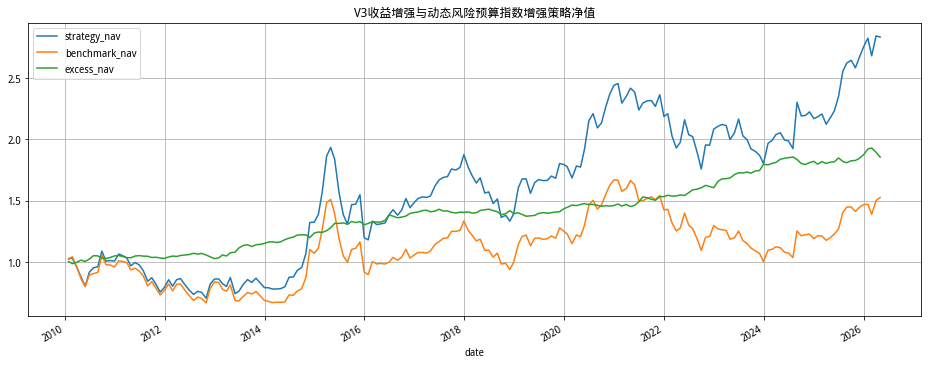

In [14]:
# =========================
# 13. 画图：净值与超额净值
# =========================

algorithm[['strategy_nav', 'benchmark_nav', 'excess_nav']].plot(
    figsize=(16, 6),
    title='V3收益增强与动态风险预算指数增强策略净值'
)
plt.grid(True)
plt.show()

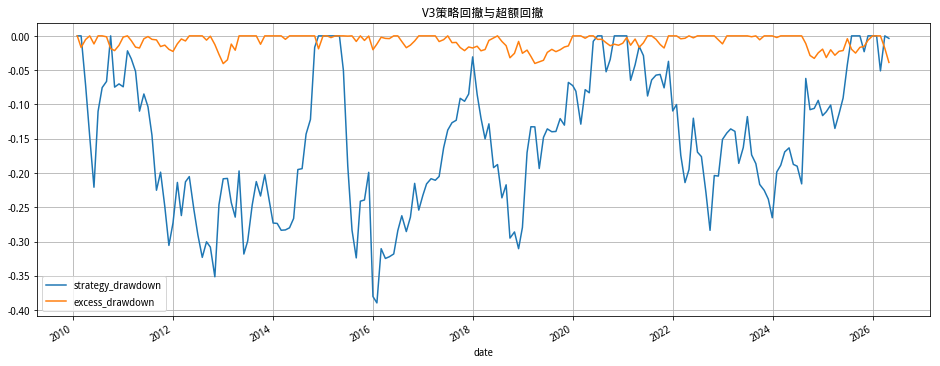

In [15]:
# =========================
# 14. 画图：回撤
# =========================

algorithm[['strategy_drawdown', 'excess_drawdown']].plot(
    figsize=(16, 6),
    title='V3策略回撤与超额回撤'
)
plt.grid(True)
plt.show()

In [16]:
# =========================
# 15. 百分比格式展示
# =========================

perf_percent = perf.copy()

percent_items = [
    '策略年化收益', '基准年化收益', '年化超额收益',
    '策略年化波动率', '年化跟踪误差',
    '策略最大回撤', '超额最大回撤',
    '月度胜率', '月均换手率'
]

for item in percent_items:
    perf_percent[item] = '{:.2%}'.format(perf[item])

perf_percent['信息比率'] = '{:.2f}'.format(perf['信息比率'])

perf_percent

策略年化收益       6.58%
基准年化收益       2.62%
年化超额收益       3.95%
策略年化波动率     21.41%
年化跟踪误差       3.82%
信息比率          0.99
策略最大回撤     -38.95%
超额最大回撤      -4.05%
月度胜率        64.29%
月均换手率       22.64%
dtype: object